# Representasi Teks ke Numerik

## Preprocessing

In [ ]:
# ============================================================
# MINI PROJECT 1 — TEXT SENTIMENT (SKINCARE REVIEWS, ID)
# ============================================================

# 0) Install dependencies (run once per fresh session)
!pip -q install textblob deep-translator Sastrawi wordcloud pandas numpy matplotlib emoji regex

# 1) Imports
import re, os, time, math, string, unicodedata, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from textblob import TextBlob
from deep_translator import GoogleTranslator
from wordcloud import WordCloud
from collections import Counter
import emoji

# Optional (stemming Indonesian)
from Sastrawi.Stemmer.StemmerFactory import StemmerFactory
stemmer = StemmerFactory().create_stemmer()

# 2) Load data
DATA_PATH = "/content/skincare_reviews_id_noise.xlsx"

# Auto-detect extension
ext = os.path.splitext(DATA_PATH)[1].lower()
if ext == ".xlsx":
    df = pd.read_excel(DATA_PATH)
else:
    df = pd.read_csv(DATA_PATH)

df.head()

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.3/42.3 kB 3.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 209.7/209.7 kB 11.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 608.4/608.4 kB 32.8 MB/s eta 0:00:00


,id,review_raw
0,1,"dipakai paagi daan maalaam, 2 pump bngt ✨"
1,2,setelah seeminggu malah makin kusam krn
2,3,Leengkeet dan laama baanget nyeraapnya
3,4,"Wangiinya nyeengaat, puusing diipaake ga ✨"
4,5,"Setelah 7 hari, kulitku lebih cerah & halus 🤔"


In [ ]:
# 3) Basic sanity check
assert "review_raw" in df.columns, "Kolom 'review_raw' harus ada pada dataset!"
df["review_raw"] = df["review_raw"].astype(str)
print("Total rows:", len(df))
print(df["review_raw"].head(5).to_string(index=False))

Total rows: 100
    dipakai paagi daan maalaam, 2 pump bngt ✨
      setelah seeminggu malah makin kusam krn
       Leengkeet dan laama baanget nyeraapnya
   Wangiinya nyeengaat, puusing diipaake ga ✨
Setelah 7 hari, kulitku lebih cerah & halus 🤔


In [ ]:
# 4) Preprocessing helpers
# ------------------------------------------------------------
# Cleaning rules:
# - remove URLs, HTML tags
# - remove @mention, hashtag symbol (tapi boleh simpan kata setelah #)
# - remove emojis (atau opsional di-keep)
# - remove punctuation, numbers, extra spaces
# - normalize elongated chars (cooool -> cool) secukupnya
# - lowercasing
# - optional: slang normalization map (simple demo)
# - stopword removal (simple list + Sastrawi stemming optional)

URL_RE = re.compile(r"http\S+|www\.\S+")        #menghapus URL atau link dari teks.
HTML_RE = re.compile(r"<.*?>")                  #menghapus HTML tags seperti <br>, <p>, <a href=...>.
MENTION_RE = re.compile(r"@\w+")                #menghapus mention seperti @username (biasanya di Twitter, Instagram, dsb).
HASHTAG_RE = re.compile(r"#(\w+)")              #mengambil atau menghapus hashtag.
NONALNUM_RE = re.compile(r"[^a-zA-Z\s]")        #menghapus semua karakter selain huruf dan spasi.
MULTISPACE_RE = re.compile(r"\s+")              #mengganti banyak spasi berurutan jadi satu spasi saja.

# contoh very-small slang map (silakan panjangin sesuai kebutuhan)
SLANG_MAP = {
    "bgt":"banget", "bngt":"banget", "bangettt":"banget", "bangeet":"banget",
    "ga":"tidak", "gak":"tidak", "nggak":"tidak",
    "tp":"tapi", "krn":"karena", "yg":"yang", "udh":"sudah", "sm":"sama", "cmn":"cuma",
    "mantul":"mantap betul", "luv":"cinta"
}

# Small Indonesian stopwords (tambahkan sesuai kebutuhan)
ID_STOP = set("""
yang dan di ke dari untuk pada dengan karena tapi atau kalau bahwa agar
itu ini saya aku kamu dia mereka kami kita tidak iya iyaaa iyaaaa iyaaaaa
sih deh dong ya kok nih tuh sih lah si dong banget bangetnya bangettt nya
""".split())

def strip_accents(s):
    return ''.join(c for c in unicodedata.normalize('NFKD', s) if not unicodedata.combining(c))

def normalize_slang(tokens):
    return [SLANG_MAP.get(t, t) for t in tokens]

def reduce_elongation(word):
    # kurangi pengulangan huruf (e.g., "baguuuusss" -> "baguus")
    return re.sub(r'(.)\1{2,}', r'\1\1', word)

def tokenize_simple(text):
    return [w for w in text.split() if w]

def clean_text_id(s,
                  keep_emojis=False,
                  do_stemming=False,
                  remove_stopwords=True):
    # remove urls & html
    s = URL_RE.sub(" ", s)
    s = HTML_RE.sub(" ", s)

    # keep hashtag words but drop '#'
    s = HASHTAG_RE.sub(lambda m: f" {m.group(1)} ", s)

    # drop mentions
    s = MENTION_RE.sub(" ", s)

    # keep or strip emojis
    if not keep_emojis:
        s = emoji.replace_emoji(s, replace=" ")

    # lower & remove accents
    s = s.lower()
    s = strip_accents(s)

    # remove punctuation & numbers
    s = NONALNUM_RE.sub(" ", s)

    # reduce elongations
    s = " ".join(reduce_elongation(w) for w in s.split())

    # collapse spaces
    s = MULTISPACE_RE.sub(" ", s).strip()

    # slang normalize
    tokens = tokenize_simple(s)
    tokens = normalize_slang(tokens)

    # stopword removal
    if remove_stopwords:
        tokens = [t for t in tokens if t not in ID_STOP and len(t) > 1]

    # stemming (optional)
    if do_stemming:
        tokens = [stemmer.stem(t) for t in tokens]

    return " ".join(tokens)

# Apply cleaning
df["clean_id"] = df["review_raw"].apply(lambda x: clean_text_id(x,
                                                                keep_emojis=False,
                                                                do_stemming=False,
                                                                remove_stopwords=True))
df[["review_raw","clean_id"]].head(10)

,review_raw,clean_id
0,"dipakai paagi daan maalaam, 2 pump bngt ✨",dipakai paagi daan maalaam pump
1,setelah seeminggu malah makin kusam krn,setelah seeminggu malah makin kusam
2,Leengkeet dan laama baanget nyeraapnya,leengkeet laama baanget nyeraapnya
3,"Wangiinya nyeengaat, puusing diipaake ga ✨",wangiinya nyeengaat puusing diipaake
4,"Setelah 7 hari, kulitku lebih cerah & halus 🤔",setelah hari kulitku lebih cerah halus
5,"Kemasaan boocoor, isiinyaa tumpaah ga #gl...",kemasaan boocoor isiinyaa tumpaah glowing skin...
6,"baru seemingguu cobaa, beluum yaakin 🙈 @tokoon...",baru seemingguu cobaa beluum yaakin jerawat
7,mahal tapi hasilnya biasa aja parah sih #jeraw...,mahal hasilnya biasa aja parah jerawat
8,"tekstur gel, warna bening, adaa sedikiit wangi...",tekstur gel warna bening adaa sedikiit wangi k...
9,butuh waktu buat lihat hasilnya krn 👍✨ pls,butuh waktu buat lihat hasilnya pls


In [ ]:
import re
import unicodedata
import emoji
import numpy as np
from Sastrawi.Stemmer.StemmerFactory import StemmerFactory

# buat stemmer
stemmer = StemmerFactory().create_stemmer()

# Regex patterns
URL_RE = re.compile(r"http\S+|www\.\S+")
HTML_RE = re.compile(r"<.*?>")
MENTION_RE = re.compile(r"@\w+")
HASHTAG_RE = re.compile(r"#(\w+)")
NONALNUM_RE = re.compile(r"[^a-zA-Z\s]")
MULTISPACE_RE = re.compile(r"\s+")

SLANG_MAP = {
    "bgt":"banget", "bngt":"banget", "bangettt":"banget", "bangeet":"banget",
    "ga":"tidak", "gak":"tidak", "nggak":"tidak", "ngga":"tidak",
    "tp":"tapi", "krn":"karena", "yg":"yang", "udh":"sudah", "sdh":"sudah",
    "sm":"sama", "cmn":"cuma", "dgn":"dengan", "jg":"juga",
    "mantul":"mantap betul", "luv":"cinta", "btw":"ngomong-ngomong",
    "pls":"tolong", "thx":"terima kasih", "makasih":"terima kasih"
}

ID_STOP = set("""
yang dan di ke dari untuk pada dengan karena tapi atau kalau bahwa agar
itu ini saya aku kamu dia mereka kami kita tidak iya iyaaa iyaaaa iyaaaaa
sih deh dong ya kok nih tuh sih lah si dong banget bangetnya bangettt nya
""".split())

def strip_accents(s):
    return ''.join(c for c in unicodedata.normalize('NFKD', s) if not unicodedata.combining(c))

def normalize_slang(tokens):
    return [SLANG_MAP.get(t, t) for t in tokens]

def reduce_elongation(word):
    return re.sub(r'(.)\1{2,}', r'\1\1', word)

def tokenize_simple(text):
    return [w for w in text.split() if w]

def clean_text_id(s, keep_emojis=False, do_stemming=False, remove_stopwords=True):
    if not isinstance(s, str) or not s.strip():
        return np.nan

    # 1. Hapus URL & HTML
    s = URL_RE.sub(" ", s)
    s = HTML_RE.sub(" ", s)

    # 2. Hashtag dan mention
    s = HASHTAG_RE.sub(lambda m: f" {m.group(1)} ", s)
    s = MENTION_RE.sub(" ", s)

    # 3. Hapus emoji (opsional)
    if not keep_emojis:
        s = emoji.replace_emoji(s, replace=" ")

    # 4. Lowercase & hilangkan aksen
    s = s.lower()
    s = strip_accents(s)

    # 5. Hilangkan tanda baca, angka, simbol
    s = NONALNUM_RE.sub(" ", s)

    # 6. Kurangi pengulangan huruf
    s = " ".join(reduce_elongation(w) for w in s.split())

    # 7. Hilangkan spasi ganda
    s = MULTISPACE_RE.sub(" ", s).strip()

    # 8. Tokenisasi
    tokens = tokenize_simple(s)

    # 9. Normalisasi slang
    tokens = normalize_slang(tokens)

    # 10. Hilangkan stopword dan kata pendek
    if remove_stopwords:
        tokens = [t for t in tokens if t not in ID_STOP and len(t) > 1]

    # 11. Stemming opsional
    if do_stemming:
        tokens = [stemmer.stem(t) for t in tokens]

    # 12. Rejoin & validasi hasil
    cleaned = " ".join(tokens)
    if len(cleaned.split()) == 0:
        return np.nan
    return cleaned

# Terapkan ke dataframe
df["clean_2"] = df["review_raw"].apply(
    lambda x: clean_text_id(
        x,
        keep_emojis=False,
        do_stemming=True,         # aktifkan stemming biar rapi
        remove_stopwords=True
    )
)

# Lihat hasil contoh
df[["review_raw", "clean_2"]].head(10)


,review_raw,clean_2
0,"dipakai paagi daan maalaam, 2 pump bngt ✨",pakai paagi daan maalaam pump
1,setelah seeminggu malah makin kusam krn,telah seeminggu malah makin kusam
2,Leengkeet dan laama baanget nyeraapnya,leengkeet laama baanget nyeraapnya
3,"Wangiinya nyeengaat, puusing diipaake ga ✨",wangi nyeengaat puusing diipaake
4,"Setelah 7 hari, kulitku lebih cerah & halus 🤔",telah hari kulit lebih cerah halus
5,"Kemasaan boocoor, isiinyaa tumpaah ga #gl...",masa boocoor isiinyaa tumpaah glowing skincare
6,"baru seemingguu cobaa, beluum yaakin 🙈 @tokoon...",baru seemingguu cobaa beluum yaakin jerawat
7,mahal tapi hasilnya biasa aja parah sih #jeraw...,mahal hasil biasa aja parah jerawat
8,"tekstur gel, warna bening, adaa sedikiit wangi...",tekstur gel warna bening adaa sedikiit wangi k...
9,butuh waktu buat lihat hasilnya krn 👍✨ pls,butuh waktu buat lihat hasil tolong


## Bag of Words (BoW) dan TF-IDF

In [ ]:
df.head(20)

,id,review_raw,clean_id,clean_2
0,1,"dipakai paagi daan maalaam, 2 pump bngt ✨",dipakai paagi daan maalaam pump,pakai paagi daan maalaam pump
1,2,setelah seeminggu malah makin kusam krn,setelah seeminggu malah makin kusam,telah seeminggu malah makin kusam
2,3,Leengkeet dan laama baanget nyeraapnya,leengkeet laama baanget nyeraapnya,leengkeet laama baanget nyeraapnya
3,4,"Wangiinya nyeengaat, puusing diipaake ga ✨",wangiinya nyeengaat puusing diipaake,wangi nyeengaat puusing diipaake
4,5,"Setelah 7 hari, kulitku lebih cerah & halus 🤔",setelah hari kulitku lebih cerah halus,telah hari kulit lebih cerah halus
5,6,"Kemasaan boocoor, isiinyaa tumpaah ga #gl...",kemasaan boocoor isiinyaa tumpaah glowing skin...,masa boocoor isiinyaa tumpaah glowing skincare
6,7,"baru seemingguu cobaa, beluum yaakin 🙈 @tokoon...",baru seemingguu cobaa beluum yaakin jerawat,baru seemingguu cobaa beluum yaakin jerawat
7,8,mahal tapi hasilnya biasa aja parah sih #jeraw...,mahal hasilnya biasa aja parah jerawat,mahal hasil biasa aja parah jerawat
8,9,"tekstur gel, warna bening, adaa sedikiit wangi...",tekstur gel warna bening adaa sedikiit wangi k...,tekstur gel warna bening adaa sedikiit wangi k...
9,10,butuh waktu buat lihat hasilnya krn 👍✨ pls,butuh waktu buat lihat hasilnya pls,butuh waktu buat lihat hasil tolong


In [ ]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
import pandas as pd


# --- Bag of Words (BoW) ---
bow_vectorizer = CountVectorizer()
bow_matrix = bow_vectorizer.fit_transform(df["clean_id"])

df_bow = pd.DataFrame(bow_matrix.toarray(), columns=bow_vectorizer.get_feature_names_out())

print("=== Bag of Words ===")
print(df_bow.tail(), "\n")

=== Bag of Words ===
    aaja  aajaa  aaplikasi  abu  acne  ada  adaa  aja  aplikasi  baanget  ...  \
95     0      0          0    0     0    0     0    0         0        0  ...   
96     0      0          0    0     0    0     0    0         0        0  ...   
97     1      0          0    0     0    0     0    0         0        0  ...   
98     0      0          0    0     0    0     0    0         0        0  ...   
99     0      0          0    0     0    0     0    0         0        0  ...   

    wangi  wangiinya  wanginya  warna  whiiteecast  whitecast  whiteecast  \
95      0          0         0      0            0          0           0   
96      0          0         0      0            0          0           0   
97      0          0         0      0            0          0           0   
98      0          0         0      0            0          0           0   
99      0          0         0      0            0          0           0   

    yaa  yaakin  yakin  
95  

In [ ]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
import pandas as pd


# --- Bag of Words (BoW) ---
bow_vectorizer = CountVectorizer()
bow_matrix = bow_vectorizer.fit_transform(df["clean_2"])

df_bow = pd.DataFrame(bow_matrix.toarray(), columns=bow_vectorizer.get_feature_names_out())

print("=== Bag of Words ===")
print(df_bow.tail(), "\n")

=== Bag of Words ===
    aaja  aajaa  aaplikasi  abu  acne  ada  adaa  aja  aplikasi  baanget  ...  \
95     0      0          0    0     0    0     0    0         0        0  ...   
96     0      0          0    0     0    0     0    0         0        0  ...   
97     1      0          0    0     0    0     0    0         0        0  ...   
98     0      0          0    0     0    0     0    0         0        0  ...   
99     0      0          0    0     0    0     0    0         0        0  ...   

    wajah  waktu  wangi  warna  whiiteecast  whitecast  whiteecast  yaa  \
95      0      0      0      0            0          0           0    0   
96      0      0      0      0            0          0           0    0   
97      0      0      0      0            0          0           0    0   
98      0      0      0      0            0          0           0    0   
99      0      0      0      0            0          0           0    0   

    yaakin  yakin  
95       0      0  
9

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
import pandas as pd

#  Inisialisasi vectorizer
tfidf_vectorizer = TfidfVectorizer(
    max_features=5000,       # ambil 5000 kata paling informatif
    ngram_range=(1,2),       # unigram + bigram
    min_df=2,                # minimal muncul di 2 dokumen
    max_df=0.8,              # abaikan kata yg muncul di >80% dokumen
    sublinear_tf=True        # pakai skema log(TF)
)

#  Fit-transform ke data teks
tfidf_matrix = tfidf_vectorizer.fit_transform(df["clean_2"])

#  Ubah jadi DataFrame biar bisa dilihat
tfidf_df = pd.DataFrame(
    tfidf_matrix.toarray(),
    columns=tfidf_vectorizer.get_feature_names_out()
)

#  Contoh: tampilkan 10 fitur teratas
print(tfidf_df.head(10))


   acne  ada  ada sedikit       aja  aplikasi  aplikasi lebih      baru  \
0   0.0  0.0          0.0  0.000000       0.0             0.0  0.000000   
1   0.0  0.0          0.0  0.000000       0.0             0.0  0.000000   
2   0.0  0.0          0.0  0.000000       0.0             0.0  0.000000   
3   0.0  0.0          0.0  0.000000       0.0             0.0  0.000000   
4   0.0  0.0          0.0  0.000000       0.0             0.0  0.000000   
5   0.0  0.0          0.0  0.000000       0.0             0.0  0.000000   
6   0.0  0.0          0.0  0.000000       0.0             0.0  0.520119   
7   0.0  0.0          0.0  0.359354       0.0             0.0  0.000000   
8   0.0  0.0          0.0  0.000000       0.0             0.0  0.000000   
9   0.0  0.0          0.0  0.000000       0.0             0.0  0.000000   

   baru seemingguu  beda  beeluum  ...  ulit  wajah  wajah tolong     wangi  \
0         0.000000   0.0      0.0  ...   0.0    0.0           0.0  0.000000   
1         0.0000

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
import pandas as pd

# Data dummy
texts = [
    "produk ini sangat bagus dan berkualitas",
    "barang ini bagus tapi agak mahal",
    "kualitas produk buruk dan tidak sesuai harapan"
]

# TF-IDF
vectorizer = TfidfVectorizer()
tfidf_matrix = vectorizer.fit_transform(texts)

# Cosine similarity antar dokumen
cosine_sim = cosine_similarity(tfidf_matrix)

# Buat DataFrame biar rapi
cosine_df = pd.DataFrame(cosine_sim, columns=[f"D{i+1}" for i in range(len(texts))], index=[f"D{i+1}" for i in range(len(texts))])
print("=== Cosine Similarity ===")
print(cosine_df)


=== Cosine Similarity ===
          D1        D2        D3
D1  1.000000  0.245272  0.224471
D2  0.245272  1.000000  0.000000
D3  0.224471  0.000000  1.000000


In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import jaccard_score
import numpy as np

texts = [
    "produk ini sangat bagus dan berkualitas",
    "barang ini bagus tapi agak mahal",
]

# TF-IDF
vectorizer = TfidfVectorizer()
tfidf = vectorizer.fit_transform(texts).toarray()

# Konversi ke biner (kata muncul = 1)
tfidf_bin = (tfidf > 0).astype(int)

# Jaccard
score = jaccard_score(tfidf_bin[0], tfidf_bin[1])
print("Jaccard Similarity:", score)


Jaccard Similarity: 0.2


# Sentiment Analysis

In [ ]:
# 5) Translate to English (for TextBlob best performance)
# ------------------------------------------------------------
# Note: Translation requires internet. If fails, we'll fallback to original 'clean_id'.
def translate_to_en(text):
    if not text or text.strip()=="":
        return text
    try:
        return GoogleTranslator(source="auto", target="en").translate(text)
    except Exception as e:
        # fallback: return the original (TextBlob can still run, but quality may drop)
        return text

# To speed up, we can cache translations
translated = []
for i, txt in enumerate(df["clean_id"].tolist()):
    tr = translate_to_en(txt)
    translated.append(tr)
    if (i+1) % 10 == 0:
        print(f"Translated {i+1}/{len(df)}")
    time.sleep(0.2)  # gentle delay to avoid rate limiting

df["clean_en"] = translated
df[["clean_id","clean_en"]].head(10)

Translated 10/100
Translated 20/100
Translated 30/100
Translated 40/100
Translated 50/100
Translated 60/100
Translated 70/100
Translated 80/100
Translated 90/100
Translated 100/100


,clean_id,clean_en
0,dipakai paagi daan maalaam pump,Daan maalaam pump
1,setelah seeminggu malah makin kusam,After a week it got even duller
2,leengkeet laama baanget nyeraapnya,Lengkeet Laama Banget Nyerapnya
3,wangiinya nyeengaat puusing diipaake,the fragrance is very pleasant to use
4,setelah hari kulitku lebih cerah halus,after the day my skin is brighter and smoother
5,kemasaan boocoor isiinyaa tumpaah glowing skin...,The Boocoor packaging contains glowing skincare
6,baru seemingguu cobaa beluum yaakin jerawat,The horror of the Semning is not the drum of d...
7,mahal hasilnya biasa aja parah jerawat,"expensive, the results are usually bad acne"
8,tekstur gel warna bening adaa sedikiit wangi k...,The clear gel texture has a slight healthy ski...
9,butuh waktu buat lihat hasilnya pls,it will take time to see the results pls


In [ ]:
# 6) Sentiment with TextBlob (polarity, subjectivity)
# ------------------------------------------------------------
def get_polarity_subj(s):
    if not isinstance(s, str) or s.strip()=="":
        return 0.0, 0.0
    tb = TextBlob(s)
    return tb.sentiment.polarity, tb.sentiment.subjectivity

pol, sub = [], []
for text in df["clean_en"].tolist():
    p, s = get_polarity_subj(text)
    pol.append(p); sub.append(s)

df["polarity"] = pol
df["subjectivity"] = sub

def label_sentiment(p):
    if p >  0.05: return "positive"
    if p < -0.05: return "negative"
    return "neutral"

df["sentiment"] = df["polarity"].apply(label_sentiment)
df["sentiment"].value_counts()

sentiment
neutral     61
positive    33
negative     6
Name: count, dtype: int64

In [ ]:
# 7) Save the processed dataset
# ------------------------------------------------------------
OUT_CSV = "/kaggle/working/skincare_reviews_processed.csv"
df.to_csv(OUT_CSV, index=False)
print("Saved:", OUT_CSV)
df.head()

Saved: /kaggle/working/skincare_reviews_processed.csv


,id,review_raw,clean_id,clean_en,polarity,subjectivity,sentiment
0,1,"dipakai paagi daan maalaam, 2 pump bngt ✨",dipakai paagi daan maalaam pump,Daan maalaam pump,0.000000,0.0,neutral
1,2,setelah seeminggu malah makin kusam krn,setelah seeminggu malah makin kusam,After a week it got even duller,0.000000,0.0,neutral
2,3,Leengkeet dan laama baanget nyeraapnya,leengkeet laama baanget nyeraapnya,Lengkeet Laama Banget Nyerapnya,0.000000,0.0,neutral
3,4,"Wangiinya nyeengaat, puusing diipaake ga ✨",wangiinya nyeengaat puusing diipaake,the fragrance is very pleasant to use,0.953333,1.0,positive
4,5,"Setelah 7 hari, kulitku lebih cerah & halus 🤔",setelah hari kulitku lebih cerah halus,after the day my skin is brighter and smoother,0.000000,0.0,neutral


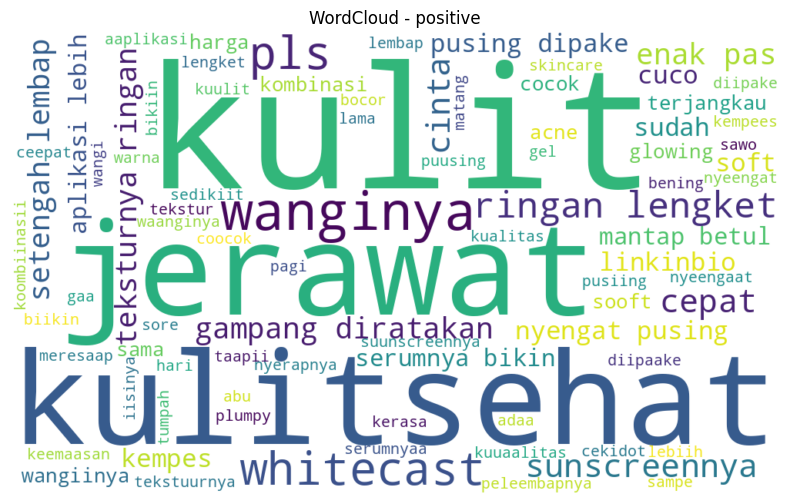

Saved: /kaggle/working/plots/wordcloud_positive.png


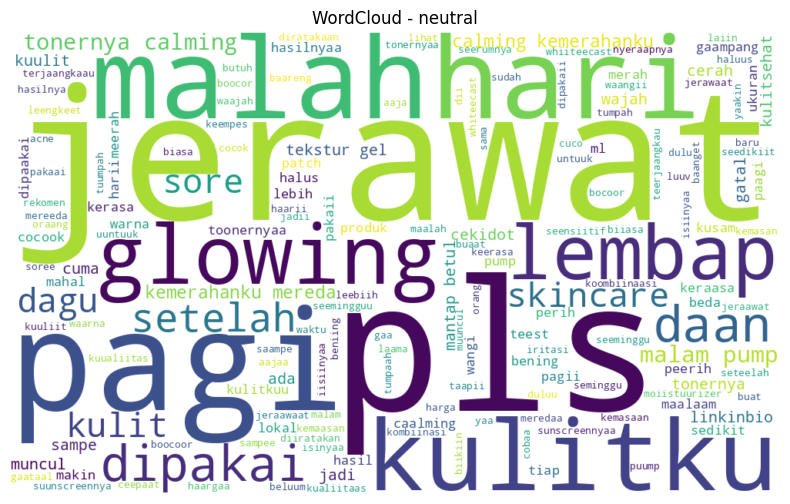

Saved: /kaggle/working/plots/wordcloud_neutral.png


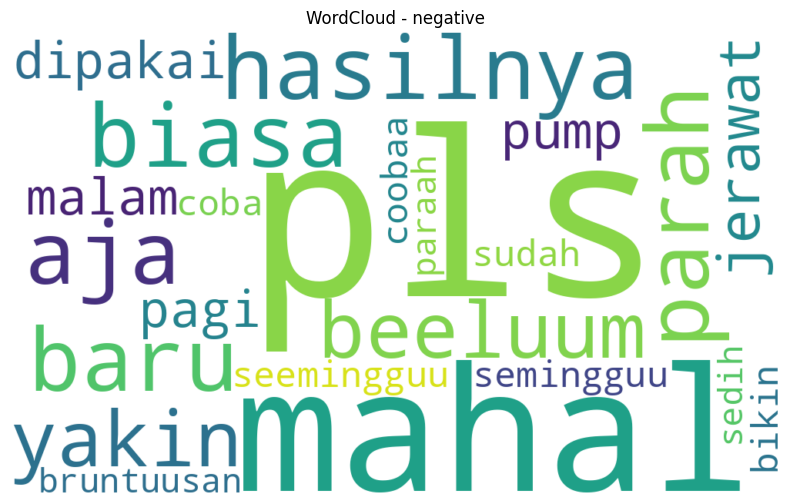

Saved: /kaggle/working/plots/wordcloud_negative.png


In [ ]:
# 8) WordCloud per sentiment
# ------------------------------------------------------------
# Prepare text for each class
def join_text(series):
    return " ".join([str(s) for s in series if isinstance(s, str)])

sentiments = ["positive","neutral","negative"]
os.makedirs("/kaggle/working/plots", exist_ok=True)

for s in sentiments:
    text_s = join_text(df.loc[df["sentiment"]==s, "clean_id"])
    if not text_s.strip():
        print(f"[WARN] No text for {s}")
        continue
    wc = WordCloud(width=1000, height=600, background_color="white").generate(text_s)
    plt.figure(figsize=(10,6))
    plt.imshow(wc, interpolation="bilinear")
    plt.axis("off")
    plt.title(f"WordCloud - {s}")
    out_path = f"/kaggle/working/plots/wordcloud_{s}.png"
    plt.savefig(out_path, bbox_inches="tight", dpi=150)
    plt.show()
    print("Saved:", out_path)

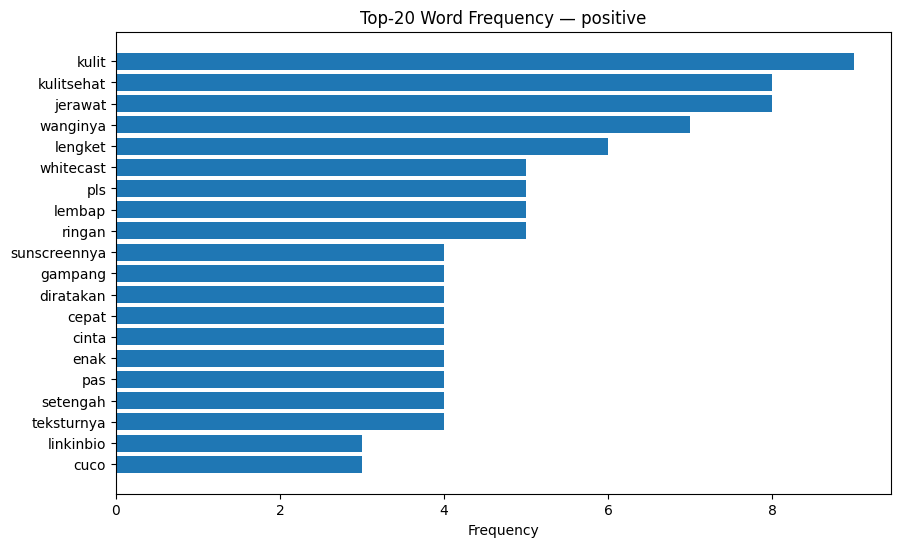

Saved: /kaggle/working/plots/wordfreq_positive.png


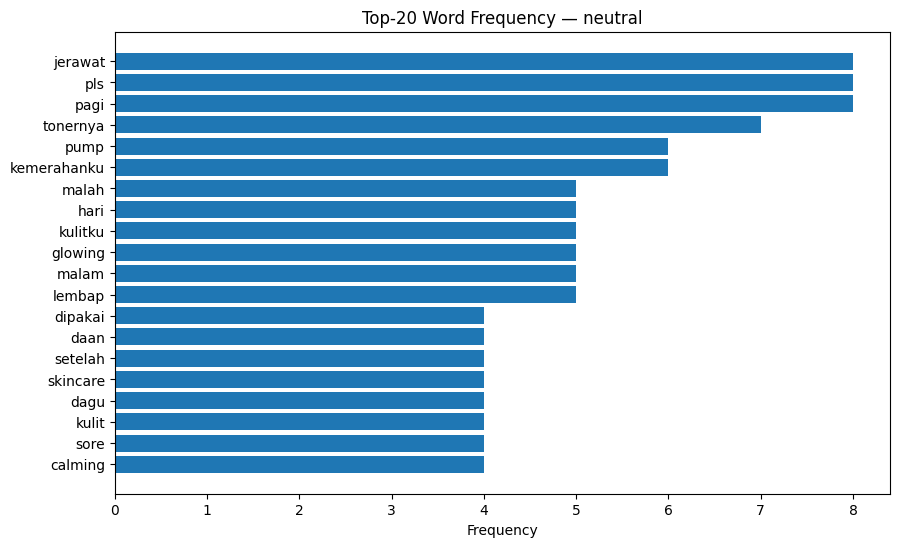

Saved: /kaggle/working/plots/wordfreq_neutral.png


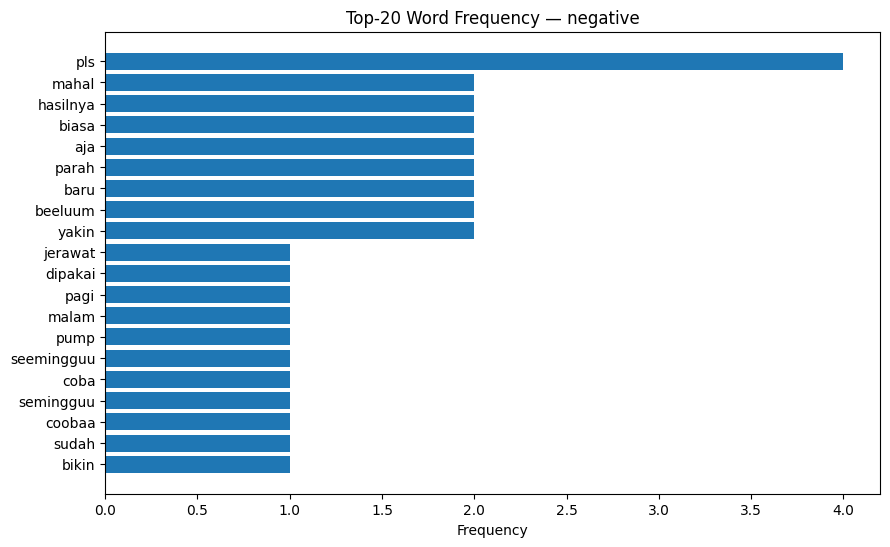

Saved: /kaggle/working/plots/wordfreq_negative.png


In [ ]:
# 9) Word Frequency Bar Chart per sentiment (Top-20)
# ------------------------------------------------------------
def get_top_words(text, topk=20):
    tokens = [t for t in text.split() if len(t) > 1]
    return Counter(tokens).most_common(topk)

for s in sentiments:
    text_s = join_text(df.loc[df["sentiment"]==s, "clean_id"])
    if not text_s.strip():
        print(f"[WARN] No text for {s}")
        continue
    top_words = get_top_words(text_s, topk=20)
    words = [w for w,_ in top_words]
    freqs = [c for _,c in top_words]

    plt.figure(figsize=(10,6))
    y_pos = np.arange(len(words))
    plt.barh(y_pos, freqs)  # matplotlib only, single plot, no custom colors
    plt.yticks(y_pos, words)
    plt.xlabel("Frequency")
    plt.title(f"Top-20 Word Frequency — {s}")
    plt.gca().invert_yaxis()
    out_path = f"/kaggle/working/plots/wordfreq_{s}.png"
    plt.savefig(out_path, bbox_inches="tight", dpi=150)
    plt.show()
    print("Saved:", out_path)

In [ ]:
# 10) Quick EDA summary by sentiment
# ------------------------------------------------------------
summary = df.groupby("sentiment").agg(
    n=("sentiment","size"),
    polarity_mean=("polarity","mean"),
    subjectivity_mean=("subjectivity","mean")
).reset_index()
summary

,sentiment,n,polarity_mean,subjectivity_mean
0,negative,6,-0.391667,0.809722
1,neutral,61,-0.001093,0.030328
2,positive,33,0.410960,0.570455


In [ ]:
sentistrength_id = pd.read_csv("https://raw.githubusercontent.com/masdevid/sentistrength_id/refs/heads/master/sentiwords_id.txt",sep=":",header=None,names=['word', 'weight'])
sentistrength_id

,word,weight
0,abadi,5
1,absen,-3
2,abu-abu,-1
3,acuh,4
4,adil,5
...,...,...
1724,wow,4
1725,wtf,-4
1726,yatim,-1
1727,yeah,3


In [ ]:
sentistrength_id.describe()

,weight
count,1729.000000
mean,-1.142279
std,3.168950
min,-5.000000
25%,-4.000000
50%,-2.000000
75%,2.000000
max,5.000000


In [ ]:
sentistrength_id_dict = pd.Series(sentistrength_id.weight.values, index=sentistrength_id.word).to_dict()
#print(inset_dict)
sentistrength_id_dict["baik"]

4

In [ ]:
sentistrength_id_dict["oke"]

3

In [ ]:
import pandas as pd
import re

# --- Load kamus sentistrength_id ---
sentistrength_id = pd.read_csv(
    "https://raw.githubusercontent.com/masdevid/sentistrength_id/refs/heads/master/sentiwords_id.txt",
    sep=":",
    header=None,
    names=["word", "weight"]
)
sentistrength_id["word"] = sentistrength_id["word"].str.strip()
sentistrength_id["weight"] = sentistrength_id["weight"].astype(int)
senti_dict = dict(zip(sentistrength_id["word"], sentistrength_id["weight"]))

subjective_words = set("""
menurut saya menurutku kurasa kupikir saya rasa saya pikir aku rasa aku pikir
kelihatannya sepertinya tampaknya kayaknya terasa mungkin agak sedikit cukup
suka cinta benci senang sedih kecewa bangga marah takut khawatir
""".split())




In [ ]:
def analyze_sentiment_metrics(teks):
    if not isinstance(teks, str):
        return pd.Series({"polarity": 0, "subjectivity": 0, "label": "netral"})

    teks = teks.lower()
    teks = re.sub(r"[^a-z\s]", " ", teks)
    tokens = teks.split()

    # --- polarity ---
    scores = [senti_dict.get(t, 0) for t in tokens]
    polarity = sum(scores) / len(scores) if tokens else 0

    # --- subjectivity ---
    subj_count = sum(1 for t in tokens if t in subjective_words)
    subjectivity = subj_count / len(tokens) if tokens else 0

    # --- label kategori ---
    if polarity > 0.1:
        label = "positif"
    elif polarity < -0.1:
        label = "negatif"
    else:
        label = "netral"

    return pd.Series({
        "polarity": polarity,
        "subjectivity": subjectivity,
        "label": label
    })


In [ ]:
df[["polarity", "subjectivity", "sentiment_label"]] = df["clean_2"].apply(analyze_sentiment_metrics)


In [ ]:
df

,id,review_raw,clean_id,clean_2,polarity,subjectivity,sentiment_label
0,1,"dipakai paagi daan maalaam, 2 pump bngt ✨",dipakai paagi daan maalaam pump,pakai paagi daan maalaam pump,0.000000,0.000000,netral
1,2,setelah seeminggu malah makin kusam krn,setelah seeminggu malah makin kusam,telah seeminggu malah makin kusam,-0.600000,0.000000,negatif
2,3,Leengkeet dan laama baanget nyeraapnya,leengkeet laama baanget nyeraapnya,leengkeet laama baanget nyeraapnya,0.000000,0.000000,netral
3,4,"Wangiinya nyeengaat, puusing diipaake ga ✨",wangiinya nyeengaat puusing diipaake,wangi nyeengaat puusing diipaake,0.000000,0.000000,netral
4,5,"Setelah 7 hari, kulitku lebih cerah & halus 🤔",setelah hari kulitku lebih cerah halus,telah hari kulit lebih cerah halus,1.166667,0.000000,positif
...,...,...,...,...,...,...,...
95,96,"serumnyaa bikiin jerawat ceepat kempees, luv b...",serumnyaa bikiin jerawat ceepat kempees cinta ...,serumnyaa bikiin jerawat ceepat kempees cinta ...,0.714286,0.142857,positif
96,97,"tonernya calming, kemerahanku mereda 🫠",tonernya calming kemerahanku mereda,tonernya calming merah reda,0.000000,0.000000,netral
97,98,mahal tapi hasilnyaa biiasa aaja 😅,mahal hasilnyaa biiasa aaja,mahal hasilnyaa biiasa aaja,-0.750000,0.000000,negatif
98,99,"dipaakai pagii daan malam, 2 puump 👍 http://bi...",dipaakai pagii daan malam puump,dipaakai pagi daan malam puump,0.000000,0.000000,netral


In [ ]:
# 10) Quick EDA summary by sentiment
# ------------------------------------------------------------
summary = (
    df.groupby("sentiment_label")
      .agg(
          n=("sentiment_label", "size"),
          polarity_mean=("polarity", "mean"),
          subjectivity_mean=("subjectivity", "mean"),
          polarity_std=("polarity", "std"),
          subjectivity_std=("subjectivity", "std")
      )
      .reset_index()
      .sort_values("polarity_mean", ascending=False)
)

summary


,sentiment_label,n,polarity_mean,subjectivity_mean,polarity_std,subjectivity_std
2,positif,22,0.911239,0.040314,0.425251,0.067841
1,netral,61,0.000000,0.006733,0.000000,0.029910
0,negatif,17,-0.708870,0.011765,0.344102,0.048507


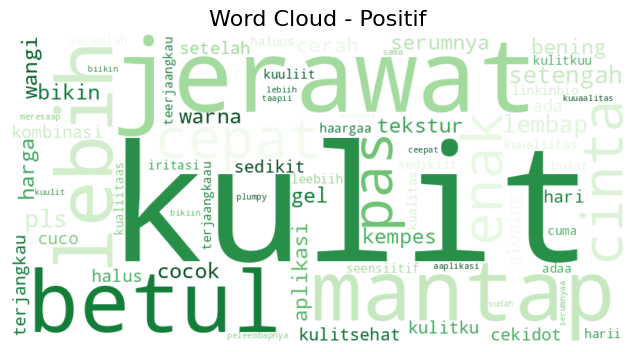

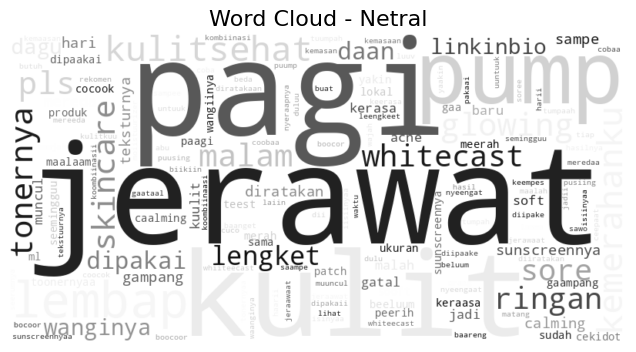

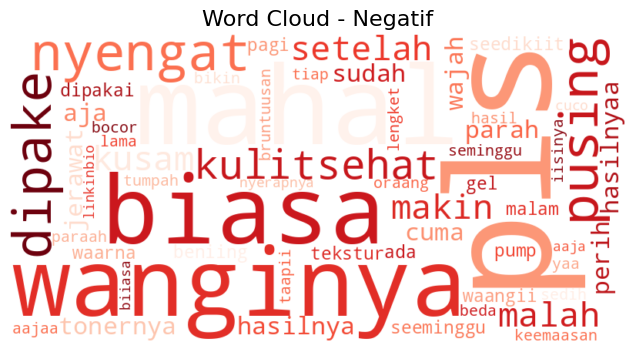

In [ ]:
from wordcloud import WordCloud
import matplotlib.pyplot as plt

# --- warna per kategori ---
colors = {
    "positif": "Greens",
    "netral": "Greys",
    "negatif": "Reds"
}

# --- fungsi pembuat wordcloud untuk 1 kategori ---
def generate_wordcloud(text, sentiment_label):
    wordcloud = WordCloud(
        width=800,
        height=400,
        background_color="white",
        colormap=colors.get(sentiment_label, "Blues"),
        max_words=200,
        collocations=False
    ).generate(text)
    return wordcloud

# --- generate per kategori ---
for sentiment in ["positif", "netral", "negatif"]:
    subset = df[df["sentiment_label"] == sentiment]

    if subset.empty:
        print(f"Tidak ada data untuk sentimen '{sentiment}' — dilewati.")
        continue

    text = " ".join(subset["clean_id"].astype(str))
    wc = generate_wordcloud(text, sentiment)

    plt.figure(figsize=(8, 4))
    plt.imshow(wc, interpolation="bilinear")
    plt.axis("off")
    plt.title(f"Word Cloud - {sentiment.capitalize()}", fontsize=16)
    plt.show()
